In [1]:
import os
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
print("Working in:", os.getcwd())

Working in: /Users/jamesfamodimu/Documents/energy-efficiency


In [9]:
import warnings; warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from statsmodels.stats.multitest import multipletests
from sklearn.model_selection import cross_val_predict

for d in ["figures", "outputs"]:
    Path(d).mkdir(exist_ok=True)
pd.set_option("display.width", 110); pd.set_option("display.max_columns", 20)
print("Setup is complete")

Setup is complete


In [15]:
import joblib
from src.data import load_data, split_data, SEED, TARGETS, NUM, CAT, THRESH

random_number_generator = np.random.default_rng(SEED)
df = load_data()
X_tr, X_te, Y_tr, Y_te = split_data(df)

features_all = df[NUM + CAT]
targets_all = df[TARGETS]

final_models = joblib.load("model/tuned_models.joblib")
logistic_regression_pipeline = joblib.load("model/logit.joblib")

print(X_tr.shape, X_te.shape, "| models:", list(final_models))


(614, 7) (154, 7) | models: ['heating_load', 'cooling_load']


In [16]:
from sklearn.model_selection import KFold, cross_val_predict

def calculate_conformal_quantile(pipeline, features, target_values):
    out_of_fold_predictions = cross_val_predict(
        estimator=pipeline, 
        X=features, 
        y=target_values, 
        cv=KFold(n_splits=10, shuffle=True, random_state=SEED), 
        n_jobs=-1
    )
    absolute_residuals = np.abs(target_values - out_of_fold_predictions)
    sample_size = len(absolute_residuals)
    
    conformal_quantile = np.quantile(
        absolute_residuals, 
        min(1.0, np.ceil((sample_size + 1) * 0.95) / sample_size)
    )
    return conformal_quantile, (target_values - out_of_fold_predictions).values

conformal_quantiles = {}
prediction_residuals = {}
conformal_records = []

for target_variable in TARGETS:
    target_quantile, target_residuals = calculate_conformal_quantile(
        pipeline=final_models[target_variable], 
        features=X_tr, 
        target_values=Y_tr[target_variable]
    )
    conformal_quantiles[target_variable] = target_quantile
    prediction_residuals[target_variable] = target_residuals
    
    test_predictions = final_models[target_variable].predict(X_te)
    test_coverage_rate = (np.abs(Y_te[target_variable] - test_predictions) <= target_quantile).mean()
    
    conformal_records.append([target_variable, target_quantile, test_coverage_rate])

conformal_results_table = pd.DataFrame(
    conformal_records, 
    columns=["target", "halfwidth_95", "test_coverage"]
)
conformal_results_table.to_csv("outputs/conformal.csv", index=False)

print(conformal_results_table.round(3))


         target  halfwidth_95  test_coverage
0  heating_load         0.804          0.987
1  cooling_load         1.882          0.994


In [18]:
model_bundle = {
    "version": "1.0.0", 
    "features": NUM + CAT, 
    "numeric": NUM, 
    "categorical": CAT,
    "models": {}, 
    "interval_halfwidth_95": {}, 
    "threshold_high_heating": THRESH,
    "valid_levels": {column: sorted(df[column].unique().tolist()) for column in NUM + CAT}
}

for target_variable in TARGETS:
    target_quantile, _ = calculate_conformal_quantile(
        pipeline=final_models[target_variable], 
        features=features_all, 
        target_values=targets_all[target_variable]
    )
    model_bundle["interval_halfwidth_95"][target_variable] = float(target_quantile)
    model_bundle["models"][target_variable] = final_models[target_variable].fit(features_all, targets_all[target_variable])

classification_target = (targets_all["heating_load"] > THRESH).astype(int)
model_bundle["high_heating_classifier"] = logistic_regression_pipeline.fit(features_all, classification_target)

joblib.dump(model_bundle, "model/energy_model.joblib")
print("Saved model/energy_model.joblib")

half_width_summary = {
    target: round(width, 3) 
    for target, width in model_bundle["interval_halfwidth_95"].items()
}
print("95% half-widths:", half_width_summary)


Saved model/energy_model.joblib
95% half-widths: {'heating_load': 0.651, 'cooling_load': 1.437}


In [21]:
%%writefile predict.py
import argparse
import warnings
from pathlib import Path
import joblib
import pandas as pd

MODEL_PATH = Path(__file__).parent / "model" / "energy_model.joblib"


def generate_predictions(input_features, model_bundle):
    features_subset = input_features[model_bundle["features"]].astype(float)
    
    out_of_grid_violations = []
    for _, row in features_subset.iterrows():
        invalid_columns = [
            col for col in model_bundle["features"] 
            if row[col] not in model_bundle["valid_levels"][col]
        ]
        out_of_grid_violations.append(", ".join(invalid_columns))
        
    if any(out_of_grid_violations):
        warnings.warn("Some inputs are outside the simulated design grid (extrapolation).")
        
    predictions_dataframe = pd.DataFrame(index=features_subset.index)
    
    for target_variable, model_pipeline in model_bundle["models"].items():
        predicted_values = model_pipeline.predict(features_subset)
        interval_halfwidth = model_bundle["interval_halfwidth_95"][target_variable]
        
        predictions_dataframe[target_variable] = predicted_values.round(2)
        predictions_dataframe[f"{target_variable}_lo95"] = (predicted_values - interval_halfwidth).round(2)
        predictions_dataframe[f"{target_variable}_hi95"] = (predicted_values + interval_halfwidth).round(2)
        
    heating_threshold = model_bundle["threshold_high_heating"]
    class_probabilities = model_bundle["high_heating_classifier"].predict_proba(features_subset)[:, 1]
    predictions_dataframe[f"p_heating_gt_{heating_threshold}"] = class_probabilities.round(3)
    
    predictions_dataframe["out_of_grid"] = out_of_grid_violations
    return predictions_dataframe


if __name__ == "__main__":
    bundle = joblib.load(MODEL_PATH)
    
    parser = argparse.ArgumentParser()
    parser.add_argument("--csv")
    parser.add_argument("--out")
    
    for feature_name in bundle["features"]:
        parser.add_argument(f"--{feature_name}", type=float)
        
    arguments = parser.parse_args()
    
    if arguments.csv:
        features_dataframe = pd.read_csv(arguments.csv)
    else:
        single_row_dictionary = {feature: getattr(arguments, feature) for feature in bundle["features"]}
        features_dataframe = pd.DataFrame([single_row_dictionary])
        
    predictions_output = generate_predictions(features_dataframe, bundle)
    
    combined_results_table = pd.concat(
        [features_dataframe.reset_index(drop=True), predictions_output.reset_index(drop=True)], 
        axis=1
    )
    
    if arguments.out:
        combined_results_table.to_csv(arguments.out, index=False)
        print("Wrote", arguments.out)
    else:
        print(combined_results_table.transpose().to_string(header=False))

Writing predict.py


In [23]:
import shlex
import subprocess
import sys

grid_building_arguments = (
    "--compactness 0.98 --wall_area 294 --roof_area 110.25 --height 7 "
    "--orientation 2 --glazing_area 0.1 --glazing_dist 1"
)
off_grid_building_arguments = (
    "--compactness 0.70 --wall_area 300 --roof_area 200 --height 3.5 "
    "--orientation 2 --glazing_area 0.1 --glazing_dist 1"
)

test_scenarios = [
    ("Grid building", grid_building_arguments), 
    ("Off-grid building", off_grid_building_arguments)
]

for label, command_arguments in test_scenarios:
    execution_result = subprocess.run(
        [sys.executable, "predict.py", *shlex.split(command_arguments)],
        capture_output=True, 
        text=True
    )
    
    print(f"===== {label} =====")
    print(execution_result.stdout)
    
    if execution_result.stderr:
        truncated_error = execution_result.stderr.strip()[-300:]
        print("Messages:", truncated_error)


===== Grid building =====
compactness          0.98
wall_area           294.0
roof_area          110.25
height                7.0
glazing_area          0.1
orientation           2.0
glazing_dist          1.0
heating_load        24.48
heating_load_lo95   23.83
heating_load_hi95   25.13
cooling_load        26.79
cooling_load_lo95   25.35
cooling_load_hi95   28.22
p_heating_gt_30     0.089
out_of_grid              

===== Off-grid building =====
compactness                                      0.7
wall_area                                      300.0
roof_area                                      200.0
height                                           3.5
glazing_area                                     0.1
orientation                                      2.0
glazing_dist                                     1.0
heating_load                                   11.17
heating_load_lo95                              10.52
heating_load_hi95                              11.82
cooling_load           

In [24]:
print(Path("predict.py").exists(), Path.cwd())

True /Users/jamesfamodimu/Documents/energy-efficiency


# Monte Carlo Simulation

In [25]:
shapes_unique_profiles = df.groupby("compactness")[["wall_area", "roof_area", "height"]].first().reset_index()
heating_load_model = model_bundle["models"]["heating_load"]

def run_monte_carlo_simulation(sample_size=100_000, allowed_heights=(3.5, 7.0), glazing_options=(0.0, 0.10, 0.25, 0.40), probabilities=None):
    filtered_shapes = shapes_unique_profiles[shapes_unique_profiles["height"].isin(allowed_heights)]
    sampled_shapes = filtered_shapes.sample(n=sample_size, replace=True, random_state=SEED).reset_index(drop=True)
    
    glazing_assignments = random_number_generator.choice(glazing_options, size=sample_size, p=probabilities)
    
    simulated_features = sampled_shapes.assign(
        orientation=random_number_generator.integers(low=2, high=6, size=sample_size),
        glazing_area=glazing_assignments,
        glazing_dist=np.where(glazing_assignments == 0, 0, random_number_generator.integers(low=1, high=6, size=sample_size))
    )[NUM + CAT]
    
    model_predictions = heating_load_model.predict(simulated_features)
    random_empirical_residuals = random_number_generator.choice(prediction_residuals["heating_load"], size=sample_size)
    
    return model_predictions + random_empirical_residuals

grid_distribution_probabilities = [1/16, 5/16, 5/16, 5/16]

simulation_scenarios = {
    "Baseline (design mix)": run_monte_carlo_simulation(probabilities=grid_distribution_probabilities),
    "Low-rise only": run_monte_carlo_simulation(allowed_heights=(3.5,), probabilities=grid_distribution_probabilities),
    "Tall, glazing 0.10": run_monte_carlo_simulation(allowed_heights=(7.0,), glazing_options=(0.10,)),
    "Tall, glazing 0.40": run_monte_carlo_simulation(allowed_heights=(7.0,), glazing_options=(0.40,))
}

monte_carlo_records = []
for scenario_name, simulated_loads in simulation_scenarios.items():
    probability_exceeding_threshold = (simulated_loads > THRESH).mean()
    standard_error = np.sqrt(probability_exceeding_threshold * (1.0 - probability_exceeding_threshold) / len(simulated_loads))
    
    confidence_interval_lower = probability_exceeding_threshold - 1.96 * standard_error
    confidence_interval_upper = probability_exceeding_threshold + 1.96 * standard_error
    
    monte_carlo_records.append([
        scenario_name, 
        simulated_loads.mean(), 
        probability_exceeding_threshold, 
        confidence_interval_lower, 
        confidence_interval_upper
    ])

columns_list = ["scenario", "mean_HL", "P_HL_gt_30", "CI_low", "CI_high"]
monte_carlo_results_table = pd.DataFrame(monte_carlo_records, columns=columns_list)
monte_carlo_results_table.to_csv("outputs/monte_carlo.csv", index=False)

print(monte_carlo_results_table.round(3))

                scenario  mean_HL  P_HL_gt_30  CI_low  CI_high
0  Baseline (design mix)   22.298       0.264   0.262    0.267
1          Low-rise only   13.323       0.000   0.000    0.000
2     Tall, glazing 0.10   28.721       0.339   0.336    0.342
3     Tall, glazing 0.40   35.246       0.846   0.844    0.849


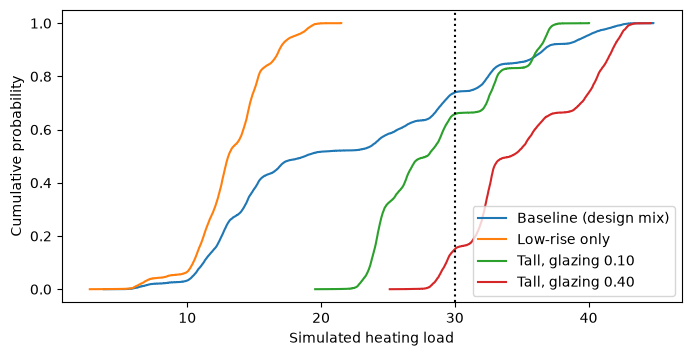

In [26]:
fig, ax = plt.subplots(figsize=(8, 3.8))

for scenario_name, simulated_loads in simulation_scenarios.items():
    sorted_subset = np.sort(simulated_loads[:20_000])
    empirical_cumulative_probabilities = np.arange(1, len(sorted_subset) + 1) / len(sorted_subset)
    ax.step(sorted_subset, empirical_cumulative_probabilities, where="post", label=scenario_name)

ax.axvline(x=THRESH, linestyle=":", color="k")
ax.set_xlabel("Simulated heating load")
ax.set_ylabel("Cumulative probability")
ax.legend()

fig.savefig("figures/05_monte_carlo.png")
plt.show()